# Analises dos dados e graficos

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('history_traduzido.csv')

In [ ]:
tipos_colunas = {
    'tempo_permanencia': 'int64',
    'cobranca_mensal': 'float64',
    'cobranca_total_acumulada': 'float64',
    'renda_mensal': 'float64',
    'id_cliente': 'string',
    'feedback_cliente': 'string',
    'idoso': 'category',
    'genero': 'category',
    'possui_companheiro': 'category',
    'possui_dependentes': 'category',
    'servico_telefonico': 'category',
    'multiplas_linhas_telefonicas': 'category',
    'servico_internet': 'category',
    'seguranca_online': 'category',
    'backup_online': 'category',
    'protecao_dispositivos': 'category',
    'suporte_tecnico': 'category',
    'streaming_tv': 'category',
    'streaming_filmes': 'category',
    'tipo_contrato': 'category',
    'faturamento_digital': 'category',
    'metodo_pagamento': 'category',
    'cancelamento_servico': 'category'
}

colunas_float = ['cobranca_mensal', 'cobranca_total_acumulada', 'renda_mensal']
colunas_int = ['idoso', 'tempo_permanencia']

for col in colunas_float + colunas_int:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        
df['idoso'] = df['idoso'].fillna(0)
df['tempo_permanencia'] = df['tempo_permanencia'].fillna(0)

df = df.astype(tipos_colunas)

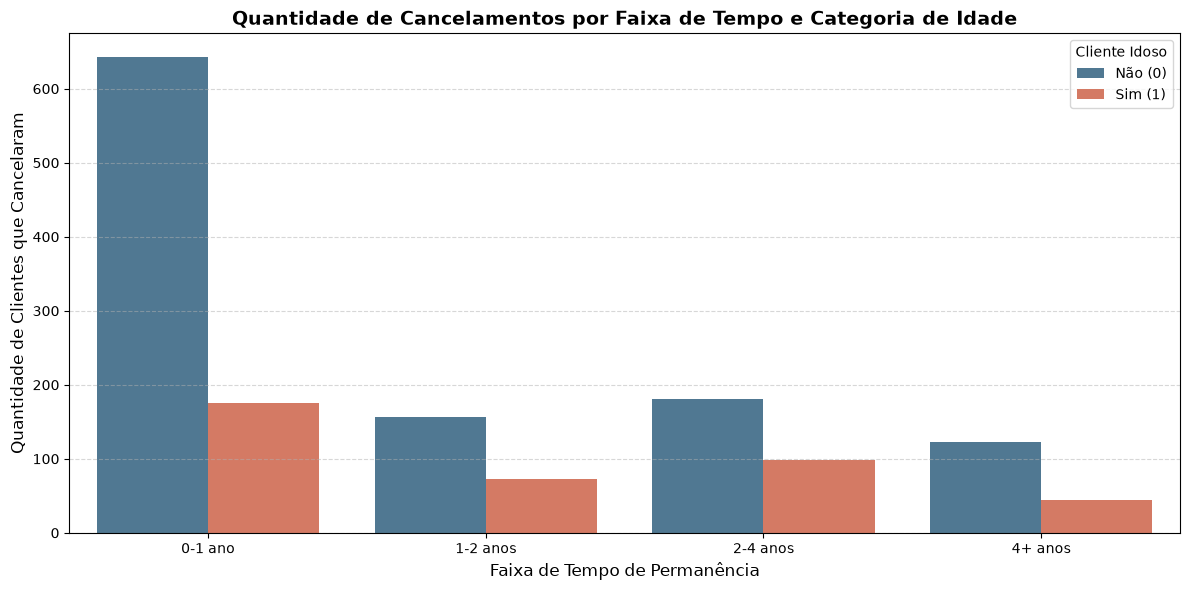

In [ ]:
# Converter a coluna para formato numérico (força conversão e ignora espaços em branco)
df['tempo_permanencia'] = pd.to_numeric(df['tempo_permanencia'], errors='coerce')

# Criar as faixas de tempo
df['faixa_permanencia'] = pd.cut(
    df['tempo_permanencia'], 
    bins=[0, 12, 24, 48, 100], 
    labels=['0-1 ano', '1-2 anos', '2-4 anos', '4+ anos'],
    include_lowest=True
)

# Gerar o gráfico
plt.figure(figsize=(12, 6))

df_cancelados = df[df['cancelamento_servico'] == 'Yes']

sns.countplot(
    data=df_cancelados,
    x='faixa_permanencia',
    hue='idoso',
    palette={0: '#457B9D', 1: '#E76F51'}
)

plt.title('Quantidade de Cancelamentos por Faixa de Tempo e Categoria de Idade', fontsize=14, fontweight='bold')
plt.xlabel('Faixa de Tempo de Permanência', fontsize=12)
plt.ylabel('Quantidade de Clientes que Cancelaram', fontsize=12)
plt.legend(title='Cliente Idoso', labels=['Não (0)', 'Sim (1)'])
plt.grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

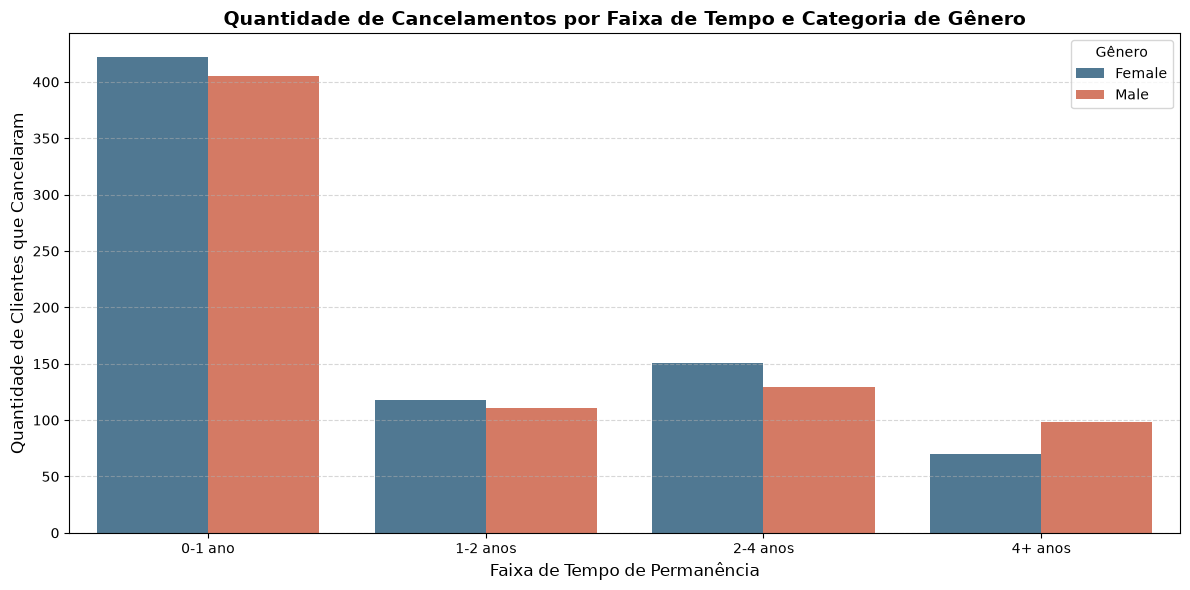

In [ ]:
df['tempo_permanencia'] = pd.to_numeric(df['tempo_permanencia'], errors='coerce')

df['faixa_permanencia'] = pd.cut(
    df['tempo_permanencia'], 
    bins=[0, 12, 24, 48, 100], 
    labels=['0-1 ano', '1-2 anos', '2-4 anos', '4+ anos'],
    include_lowest=True
)

plt.figure(figsize=(12, 6))

df_cancelados = df[df['cancelamento_servico'] == 'Yes']

sns.countplot(
    data=df_cancelados,
    x='faixa_permanencia',
    hue='genero',
    palette=['#457B9D', '#E76F51']  # Passando como lista, o Seaborn atribui as cores automaticamente
)

plt.title('Quantidade de Cancelamentos por Faixa de Tempo e Categoria de Gênero', fontsize=14, fontweight='bold')
plt.xlabel('Faixa de Tempo de Permanência', fontsize=12)
plt.ylabel('Quantidade de Clientes que Cancelaram', fontsize=12)
plt.legend(title='Gênero')
plt.grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Palavras de destaque no feedback do cliente

Os comentários da coluna `feedback_cliente` estão em inglês. O modelo DistilBERT, da biblioteca `transformers`, dá uma nota de sentimento para cada palavra. Quem cancelou fica com as 5 palavras mais negativas. Quem permaneceu fica com as 5 palavras mais positivas. O resultado entra na coluna `palavras_relevantes`.

Uma negação perto da palavra inverte a nota: `reliable` é positiva, mas `not reliable` entra como termo negativo. Palavras muito repetidas, como `satisfied`, `however` e `unfortunately`, ficam de fora. Quando um adjetivo está ligado a um substantivo, os dois entram juntos, como `slow internet` ou `steep charges`.

As duas últimas células montam uma nuvem de palavras para cada grupo, com o que mais se repete.


In [5]:
import re
from collections import Counter
from transformers import pipeline
from wordcloud import WordCloud

modelo_sentimento = pipeline(
    'sentiment-analysis',
    model='distilbert-base-uncased-finetuned-sst-2-english',
)


C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\moham\.cache\huggingface\hub\models--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an

In [6]:
padrao_palavra = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")

stopwords = {
    'i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'you', 'your', 'yours',
    'he', 'him', 'his', 'she', 'her', 'hers', 'it', 'its', 'they', 'them', 'their',
    'this', 'that', 'these', 'those', 'a', 'an', 'the', 'and', 'or', 'but', 'if',
    'because', 'as', 'of', 'at', 'by', 'for', 'with', 'about', 'into', 'through',
    'during', 'before', 'after', 'to', 'from', 'in', 'out', 'on', 'off', 'over',
    'under', 'again', 'then', 'once', 'here', 'there', 'when', 'where', 'why', 'how',
    'all', 'any', 'both', 'each', 'few', 'more', 'most', 'other', 'some', 'such',
    'only', 'own', 'same', 'so', 'than', 'too', 'very', 'can', 'will', 'just',
    'should', 'now', 'have', 'has', 'had', 'having', 'do', 'does', 'did', 'doing',
    'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'what', 'which', 'who',
    'whom', 'would', 'could', 'ive', 'im', 'id', 'ill', 'youre', 'theyre', 'thats',
    'also', 'really', 'there', 'here',
}

# Palavras que se repetem e não explicam o motivo.
# satisfied entra aqui: sozinha aparece em quase todo comentário.
# not satisfied continua, porque a negação muda o sentido.
# internet, service, price e charge saíram desta lista para formar dupla
# com o adjetivo ligado, como slow internet ou steep charges.
palavras_genericas = {
    'customer', 'customers', 'company', 'month', 'months', 'monthly',
    'year', 'years', 'time', 'overall', 'dsl', 'fiber', 'optic',
    'check', 'credit', 'card', 'bank', 'churn', 'cancel', 'canceled',
    'cancelled', 'cancellation', 'switch', 'switched', 'switching',
    'decided', 'decision', 'satisfied', 'satisfaction', 'appreciate',
    'appreciated', 'however', 'while', 'although', 'though',
    'unfortunately', 'recently', 'ultimately', 'initially', 'finally',
    'despite', 'another', 'elsewhere', 'reason', 'reasons', 'bit',
    'half', 'almost', 'compared', 'comparison', 'find', 'found',
    'consider', 'considered', 'others', 'provided', 'felt', 'using',
    'use', 'used', 'electronic', 'automatic', 'mailed', 'able', 'makes',
    'made', 'make', 'highly', 'additionally', 'already', 'still', 'even',
    'via', 'per', 'term', 'terms', 'method', 'methods', 'process',
    'needs', 'need', 'similar', 'chose', 'chosen', 'expected', 'expecting',
    'mail', 'mailing', 'transfer', 'transfers', 'option', 'options',
    'back', 'get', 'got', 'going', 'went', 'like', 'quite', 'rather',
    'currently', 'generally', 'worth', 'one', 'part', 'parts', 'way',
    'thing', 'things', 'something', 'anything', 'lot', 'lots',
}

negacoes = {
    'not', 'no', 'never', 'without', 'hardly', 'nor', 'neither', 'cannot',
    'dont', 'doesnt', 'didnt', 'isnt', 'arent', 'wasnt', 'werent',
    'havent', 'hasnt', 'hadnt', 'cant', 'couldnt', 'wont', 'wouldnt', 'shouldnt',
}

# Substantivo que pode grudar no adjetivo ao lado.
nucleos = {
    'internet', 'service', 'services', 'provider', 'providers', 'phone',
    'connection', 'speed', 'speeds', 'price', 'prices', 'cost', 'costs',
    'charge', 'charges', 'bill', 'bills', 'billing', 'payment', 'payments',
    'contract', 'support', 'quality', 'experience', 'outage', 'outages',
    'value', 'signal', 'coverage', 'fee', 'fees', 'network', 'installation',
    'technician', 'staff', 'streaming', 'reliability', 'wifi', 'data',
}

# Adjetivo que forma a dupla, na ordem da frase ou na ordem invertida.
modificadores = {
    'slow', 'fast', 'high', 'low', 'poor', 'bad', 'good', 'great',
    'expensive', 'cheap', 'unreliable', 'reliable', 'excellent',
    'terrible', 'frustrating', 'inconsistent', 'outdated', 'steep',
    'convenient', 'inconvenient', 'affordable', 'reasonable',
    'competitive', 'uncompetitive', 'modern', 'limited', 'stable',
    'unstable', 'horrible', 'awful', 'higher', 'lower', 'slower',
    'faster', 'worse', 'better', 'difficult', 'easy', 'hard',
    'frequent', 'constant', 'weak', 'strong', 'overpriced', 'costly',
    'quick', 'delayed', 'late', 'extra', 'hidden', 'rude', 'helpful',
    'unhelpful', 'friendly', 'smooth', 'positive', 'negative', 'long',
    'short', 'dropped', 'intermittent', 'lack', 'lacking', 'loyal',
    'happy', 'unhappy', 'pleased', 'wonderful', 'decent', 'fair',
}

# Sozinhas não entram. Só sobrevivem grudadas no substantivo.
so_em_frase = {
    'high', 'low', 'good', 'bad', 'great', 'long', 'short', 'fast',
    'higher', 'lower', 'extra', 'big', 'small', 'new', 'old',
}


def tokenizar(texto):
    if not isinstance(texto, str) or not texto.strip():
        return []

    tokens = [t.lower().replace("'", '') for t in padrao_palavra.findall(texto)]
    palavras = []
    anterior = None
    afastamento = 0
    negacao_ativa = False
    limite_ligacao = 8

    def soltar_anterior():
        nonlocal anterior, afastamento
        if anterior is None:
            afastamento = 0
            return
        token_ant, tipo, neg_ant = anterior
        anterior = None
        afastamento = 0
        if tipo == 'mod' and token_ant not in so_em_frase:
            palavras.append((token_ant, neg_ant))
        elif tipo == 'nucleo' and neg_ant:
            palavras.append((token_ant, neg_ant))

    for token in tokens:
        if anterior is not None:
            afastamento += 1
            if afastamento > limite_ligacao:
                soltar_anterior()

        if token in negacoes:
            negacao_ativa = True
            continue

        if token in stopwords or len(token) <= 2:
            continue

        negada = negacao_ativa
        if token in palavras_genericas and not negada:
            continue

        negacao_ativa = False

        if token in nucleos:
            if anterior is not None and anterior[1] == 'mod':
                modificador, _, neg_mod = anterior
                palavras.append((f'{modificador} {token}', neg_mod or negada))
                anterior = None
                afastamento = 0
            else:
                if anterior is not None and anterior[1] == 'nucleo' and anterior[2]:
                    palavras.append((anterior[0], True))
                anterior = (token, 'nucleo', negada)
                afastamento = 0
            continue

        if token in modificadores:
            if anterior is not None and anterior[1] == 'nucleo':
                nucleo, _, neg_nuc = anterior
                palavras.append((f'{token} {nucleo}', negada or neg_nuc))
                anterior = None
                afastamento = 0
            else:
                if anterior is not None and anterior[1] == 'mod' and anterior[0] not in so_em_frase:
                    palavras.append((anterior[0], anterior[2]))
                anterior = (token, 'mod', negada)
                afastamento = 0
            continue

        soltar_anterior()
        palavras.append((token, negada))

    soltar_anterior()
    return palavras


vocabulario = sorted({
    palavra
    for texto in df['feedback_cliente'].fillna('')
    for palavra, _ in tokenizar(texto)
})
print(f'Palavras únicas para classificar: {len(vocabulario)}')

pontuacao_palavra = {}
tamanho_lote = 128

for inicio in range(0, len(vocabulario), tamanho_lote):
    lote = vocabulario[inicio:inicio + tamanho_lote]
    resultados = modelo_sentimento(lote, batch_size=tamanho_lote, truncation=True)

    for palavra, resultado in zip(lote, resultados):
        if isinstance(resultado, list):
            resultado = resultado[0]
        rotulo = str(resultado['label']).upper()
        nota = float(resultado['score'])
        # Positivo fica entre 0 e 1. Negativo fica entre -1 e 0.
        pontuacao_palavra[palavra] = -nota if 'NEG' in rotulo else nota

print('Classificação de sentimento concluída.')


Palavras únicas para classificar: 975
Classificação de sentimento concluída.


In [7]:
def cinco_palavras(texto, cancelou):
    ocorrencias = tokenizar(texto)
    if not ocorrencias:
        return ''

    notas = {}
    for palavra, negada in ocorrencias:
        nota = pontuacao_palavra.get(palavra, 0.0)
        if negada:
            nota = -nota
            chave = f'not {palavra}'
        else:
            chave = palavra

        if chave not in notas:
            notas[chave] = nota
        elif cancelou:
            notas[chave] = min(notas[chave], nota)
        else:
            notas[chave] = max(notas[chave], nota)

    # Cancelou: as 5 notas mais baixas. Permaneceu: as 5 notas mais altas.
    ordenadas = sorted(notas.items(), key=lambda item: item[1], reverse=not cancelou)
    return ', '.join(chave for chave, _ in ordenadas[:5])


def frequencia_palavras(mascara):
    contagem = Counter()
    serie = df.loc[mascara, 'palavras_relevantes'].fillna('')
    for item in serie:
        for parte in str(item).split(', '):
            parte = parte.strip()
            if parte:
                contagem[parte] += 1
    return contagem


df['palavras_relevantes'] = [
    cinco_palavras(texto, str(cancelou) == 'Yes')
    for texto, cancelou in zip(df['feedback_cliente'], df['cancelamento_servico'])
]

colunas_amostra = ['cancelamento_servico', 'palavras_relevantes', 'feedback_cliente']
amostra_cancelou = df.loc[df['cancelamento_servico'].astype(str) == 'Yes', colunas_amostra].head(3)
amostra_retido = df.loc[df['cancelamento_servico'].astype(str) == 'No', colunas_amostra].head(3)
amostra = pd.concat([amostra_cancelou, amostra_retido])
amostra['feedback_cliente'] = amostra['feedback_cliente'].astype(str).str.slice(0, 160)
amostra


,cancelamento_servico,palavras_relevantes,feedback_cliente
1,Yes,"outdated, unfortunately, inconvenient, steep, ...",I've been a customer with this company for ove...
5,Yes,"however, initially, another, transfers, cost",I have been a customer with this company for 7...
7,Yes,"however, felt, recently, ultimately, payments",I recently canceled my service with this provi...
0,No,"happy, reliable, appreciate, satisfied, reason...",I have been a customer with this internet prov...
2,No,"able, appreciate, affordable, satisfied, not p...",I have been a customer with this company for 2...
3,No,"happy, reliable, appreciate, satisfied, reason...",I have been a customer with this internet prov...


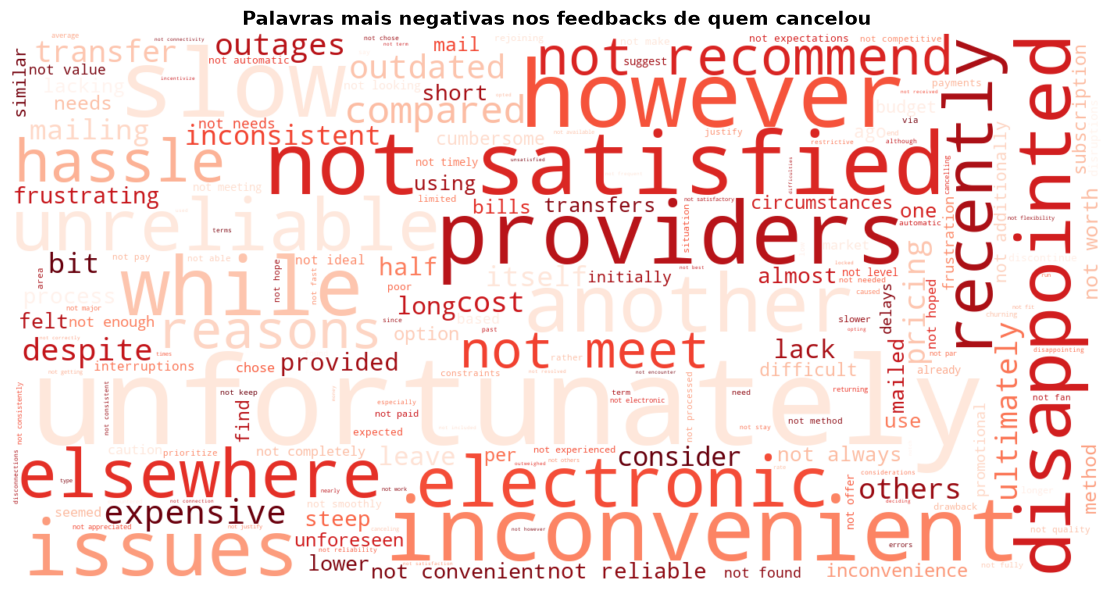

In [8]:
contagem_cancelou = frequencia_palavras(df['cancelamento_servico'].astype(str) == 'Yes')

if not contagem_cancelou:
    print('Não há palavras para a nuvem de quem cancelou.')
else:
    nuvem_cancelou = WordCloud(
        width=1400,
        height=700,
        background_color='white',
        colormap='Reds',
        collocations=False,
        random_state=42,
    ).generate_from_frequencies(contagem_cancelou)

    plt.figure(figsize=(12, 6))
    plt.imshow(nuvem_cancelou, interpolation='bilinear')
    plt.axis('off')
    plt.title('Palavras mais negativas nos feedbacks de quem cancelou', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


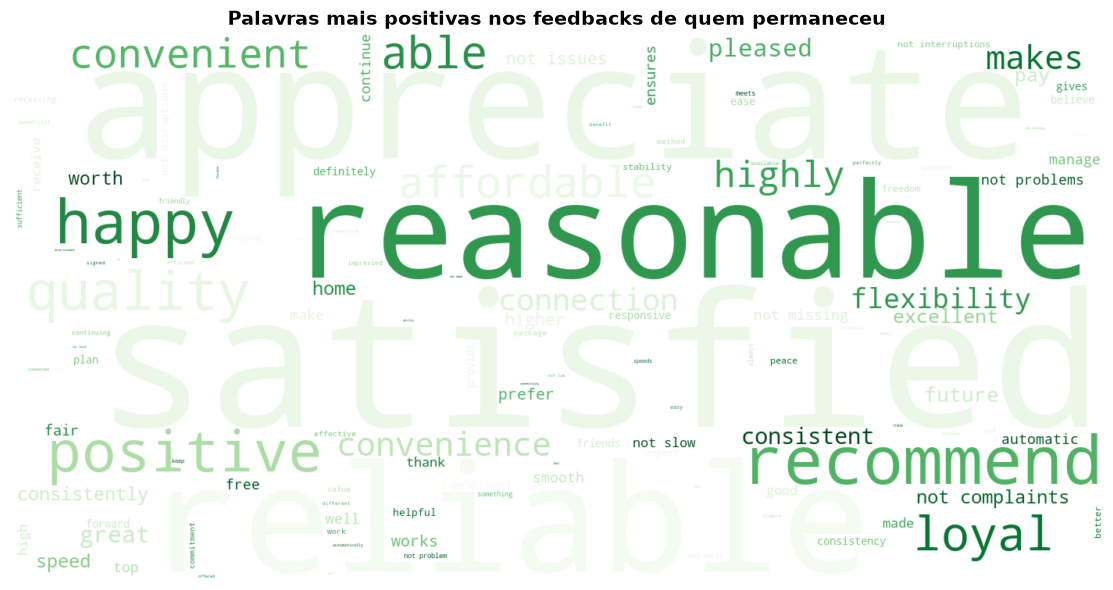

In [9]:
contagem_retido = frequencia_palavras(df['cancelamento_servico'].astype(str) == 'No')

if not contagem_retido:
    print('Não há palavras para a nuvem de quem permaneceu.')
else:
    nuvem_retido = WordCloud(
        width=1400,
        height=700,
        background_color='white',
        colormap='Greens',
        collocations=False,
        random_state=42,
    ).generate_from_frequencies(contagem_retido)

    plt.figure(figsize=(12, 6))
    plt.imshow(nuvem_retido, interpolation='bilinear')
    plt.axis('off')
    plt.title('Palavras mais positivas nos feedbacks de quem permaneceu', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


## Perfil de quem sai e de quem permanece

Cada atributo é comparado com o que já aconteceu na base. Para cada valor, a taxa de saída do grupo é colocada ao lado da taxa geral. Se a taxa do grupo fica acima da geral, aquele valor acompanhou mais cancelamentos. Se fica abaixo, acompanhou mais permanência.

O impacto de uma coluna é a distância entre o valor que mais acompanhou saída e o valor que mais acompanhou permanência. O pior perfil reúne, coluna por coluna, o valor de maior taxa de saída. O melhor perfil reúne o de menor taxa. Entra na conta apenas valor com pelo menos 50 clientes, para um grupo pequeno não distorcer a leitura.

Esse perfil empilha o extremo de cada coluna. Ele descreve a combinação mais associada à saída, ou à permanência, no passado. Não é uma pessoa real obrigatoriamente presente na base.


In [10]:
df_perfil = df.copy()
df_perfil['saiu'] = (df_perfil['cancelamento_servico'].astype(str) == 'Yes').astype(int)

taxa_geral = df_perfil['saiu'].mean()
minimo_clientes = 50

colunas_categoricas = [
    'genero', 'idoso', 'possui_companheiro', 'possui_dependentes',
    'servico_telefonico', 'multiplas_linhas_telefonicas', 'servico_internet',
    'seguranca_online', 'backup_online', 'protecao_dispositivos', 'suporte_tecnico',
    'streaming_tv', 'streaming_filmes', 'tipo_contrato', 'faturamento_digital',
    'metodo_pagamento',
]

colunas_numericas = [
    'tempo_permanencia', 'cobranca_mensal', 'cobranca_total_acumulada', 'renda_mensal',
]


def faixa_numerica(serie, nome):
    numeros = pd.to_numeric(serie, errors='coerce')
    faixas = pd.qcut(numeros, q=4, duplicates='drop')
    casas = 0 if nome == 'tempo_permanencia' else 1
    rotulos = [
        f'{intervalo.left:.{casas}f} até {intervalo.right:.{casas}f}'
        for intervalo in faixas.cat.categories
    ]
    faixas = faixas.cat.rename_categories(rotulos)
    return faixas.astype(str).replace('nan', 'Sem informação').rename(nome)


partes = []

for coluna in colunas_categoricas:
    serie = df_perfil[coluna].astype(str).replace({'nan': 'Sem informação', 'None': 'Sem informação'})
    if coluna == 'idoso':
        serie = serie.replace({'0': 'Não', '1': 'Sim', '0.0': 'Não', '1.0': 'Sim'})

    grupo = (
        df_perfil.groupby(serie, dropna=False)['saiu']
        .agg(clientes='size', sairam='sum')
        .reset_index()
        .rename(columns={serie.name: 'valor'})
    )
    grupo['coluna'] = coluna
    partes.append(grupo)

for coluna in colunas_numericas:
    rotulo = faixa_numerica(df_perfil[coluna], coluna)
    grupo = (
        df_perfil.groupby(rotulo, dropna=False)['saiu']
        .agg(clientes='size', sairam='sum')
        .reset_index()
        .rename(columns={rotulo.name: 'valor'})
    )
    grupo['coluna'] = coluna
    partes.append(grupo)

relacao = pd.concat(partes, ignore_index=True)
relacao['taxa_saida'] = relacao['sairam'] / relacao['clientes']
relacao['diferenca_pp'] = (relacao['taxa_saida'] - taxa_geral) * 100
relacao = relacao[relacao['clientes'] >= minimo_clientes].copy()
relacao = relacao[['coluna', 'valor', 'clientes', 'sairam', 'taxa_saida', 'diferenca_pp']]
relacao = relacao.sort_values(['coluna', 'diferenca_pp'], ascending=[True, False]).reset_index(drop=True)

print(f'Taxa geral de saída: {taxa_geral:.1%}')
print(f'Só entra valor com pelo menos {minimo_clientes} clientes.')
relacao


Taxa geral de saída: 26.7%
Só entra valor com pelo menos 50 clientes.


,coluna,valor,clientes,sairam,taxa_saida,diferenca_pp
0,backup_online,No,2457,981,0.399267,13.231674
1,backup_online,Yes,1944,434,0.223251,-4.369963
2,backup_online,No internet service,1233,89,0.072182,-19.476899
3,cobranca_mensal,70.3 até 89.8,1409,526,0.373314,10.636375
4,cobranca_mensal,89.8 até 118.7,1407,476,0.338308,7.135780
5,cobranca_mensal,35.2 até 70.3,1409,347,0.246274,-2.067670
6,cobranca_mensal,18.4 até 35.2,1409,155,0.110007,-15.694356
7,cobranca_total_acumulada,-0.0 até 402.6,1410,600,0.425532,15.858126
8,cobranca_total_acumulada,402.6 até 1390.6,1407,363,0.257996,-0.895492
9,cobranca_total_acumulada,1390.6 até 3756.4,1408,333,0.236506,-3.044497


## Probabilidade de saída de cada cliente

A **taxa geral** é a saída da base inteira:

taxa geral = clientes que saíram / todos os clientes

A **taxa de saída** de um valor é a saída só de quem tem aquele valor na coluna:

taxa de saída = clientes com aquele valor que saíram / clientes com aquele valor

Exemplo: se 200 pessoas têm `multiplas_linhas_telefonicas` = `No phone service` e 80 saíram, a taxa desse valor é 80 / 200 = 40%. Se a taxa geral da base é 27%, esse valor fica cerca de 13 pontos percentuais acima do comum. Nas colunas numéricas, o valor é a faixa (os quartis), e a conta é a mesma.

A **probabilidade total** do cliente junta essas taxas. Para cada atributo, a célula pega a taxa de saída do valor que aquela pessoa tem. A coluna `probabilidade_saida` é a média dessas taxas:

probabilidade de saída = soma das taxas de saída dos atributos do cliente / quantidade de atributos

Quem já saiu também recebe a coluna. A conta não olha se aquela pessoa saiu ou ficou. Ela olha com que frequência pessoas com os mesmos atributos saíram no passado. Valor com menos de 50 clientes não tem taxa própria e entra na média como a taxa geral.

In [ ]:
taxas_por_valor = {
    (linha.coluna, str(linha.valor)): float(linha.taxa_saida)
    for linha in relacao.itertuples(index=False)
}


def rotulo_do_cliente(coluna):
    if coluna in colunas_numericas:
        return faixa_numerica(df_perfil[coluna], coluna).astype(str)

    serie = df_perfil[coluna].astype(str).replace({'nan': 'Sem informação', 'None': 'Sem informação'})
    if coluna == 'idoso':
        serie = serie.replace({'0': 'Não', '1': 'Sim', '0.0': 'Não', '1.0': 'Sim'})
    return serie


colunas_perfil = colunas_categoricas + colunas_numericas
taxas_cliente = pd.DataFrame(index=df_perfil.index)

for coluna in colunas_perfil:
    rotulos = rotulo_do_cliente(coluna)
    taxas_cliente[coluna] = [
        taxas_por_valor.get((coluna, valor), taxa_geral)
        for valor in rotulos
    ]

df_perfil['probabilidade_saida'] = taxas_cliente.mean(axis=1)
df['probabilidade_saida'] = df_perfil['probabilidade_saida']

print(f'Taxa geral da base: {taxa_geral:.1%}')
print(
    'Média da probabilidade entre quem saiu:',
    f"{df_perfil.loc[df_perfil['saiu'] == 1, 'probabilidade_saida'].mean():.1%}",
)
print(
    'Média da probabilidade entre quem ficou:',
    f"{df_perfil.loc[df_perfil['saiu'] == 0, 'probabilidade_saida'].mean():.1%}",
)

df_perfil[['cancelamento_servico', 'probabilidade_saida']].head(8)

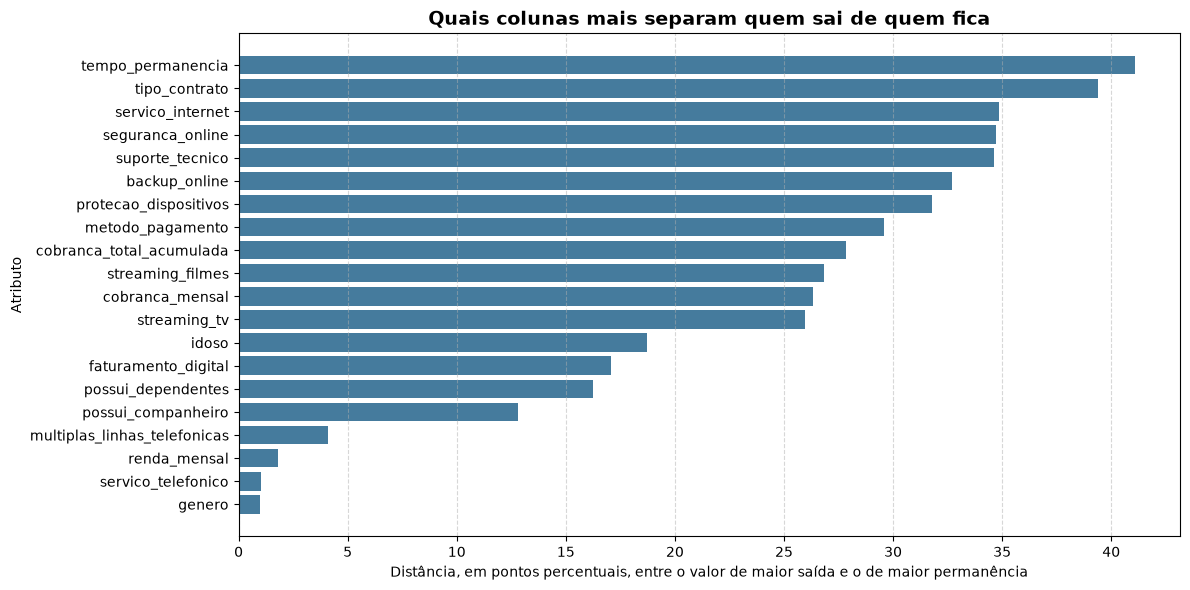

,coluna,taxa_mais_alta,taxa_mais_baixa,impacto_pp
0,tempo_permanencia,0.490541,0.079570,41.097065
1,tipo_contrato,0.426589,0.032665,39.392404
2,servico_internet,0.420670,0.072182,34.848849
3,seguranca_online,0.419194,0.072182,34.701205
4,suporte_tecnico,0.418488,0.072182,34.630633
5,backup_online,0.399267,0.072182,32.708573
6,protecao_dispositivos,0.390036,0.072182,31.785478
7,metodo_pagamento,0.451271,0.155592,29.567961
8,cobranca_total_acumulada,0.425532,0.147017,27.851487
9,streaming_filmes,0.340378,0.072182,26.819603


In [11]:
impacto_coluna = (
    relacao.groupby('coluna')
    .agg(taxa_mais_alta=('taxa_saida', 'max'), taxa_mais_baixa=('taxa_saida', 'min'))
    .reset_index()
)
impacto_coluna['impacto_pp'] = (impacto_coluna['taxa_mais_alta'] - impacto_coluna['taxa_mais_baixa']) * 100
impacto_coluna = impacto_coluna.sort_values('impacto_pp', ascending=False).reset_index(drop=True)

impacto_plot = impacto_coluna.sort_values('impacto_pp', ascending=True)

plt.figure(figsize=(12, 6))
plt.barh(impacto_plot['coluna'], impacto_plot['impacto_pp'], color='#457B9D')
plt.title('Quais colunas mais separam quem sai de quem fica', fontsize=14, fontweight='bold')
plt.xlabel('Distância, em pontos percentuais, entre o valor de maior saída e o de maior permanência')
plt.ylabel('Atributo')
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

impacto_coluna


Valores que aumentam a possibilidade de sair, frente ao que aconteceu na base:
Coluna tempo_permanencia com o valor "-0 até 9" aumenta a possibilidade de sair: taxa de 49.1% contra 26.7% na base (+22.4 pontos percentuais; 1480 clientes).
Coluna metodo_pagamento com o valor "Electronic check" aumenta a possibilidade de sair: taxa de 45.1% contra 26.7% na base (+18.4 pontos percentuais; 1888 clientes).
Coluna tipo_contrato com o valor "Month-to-month" aumenta a possibilidade de sair: taxa de 42.7% contra 26.7% na base (+16.0 pontos percentuais; 3099 clientes).
Coluna cobranca_total_acumulada com o valor "-0.0 até 402.6" aumenta a possibilidade de sair: taxa de 42.6% contra 26.7% na base (+15.9 pontos percentuais; 1410 clientes).
Coluna idoso com o valor "Sim" aumenta a possibilidade de sair: taxa de 42.3% contra 26.7% na base (+15.7 pontos percentuais; 928 clientes).
Coluna servico_internet com o valor "Fiber optic" aumenta a possibilidade de sair: taxa de 42.1% contra 26.7% na base (+15

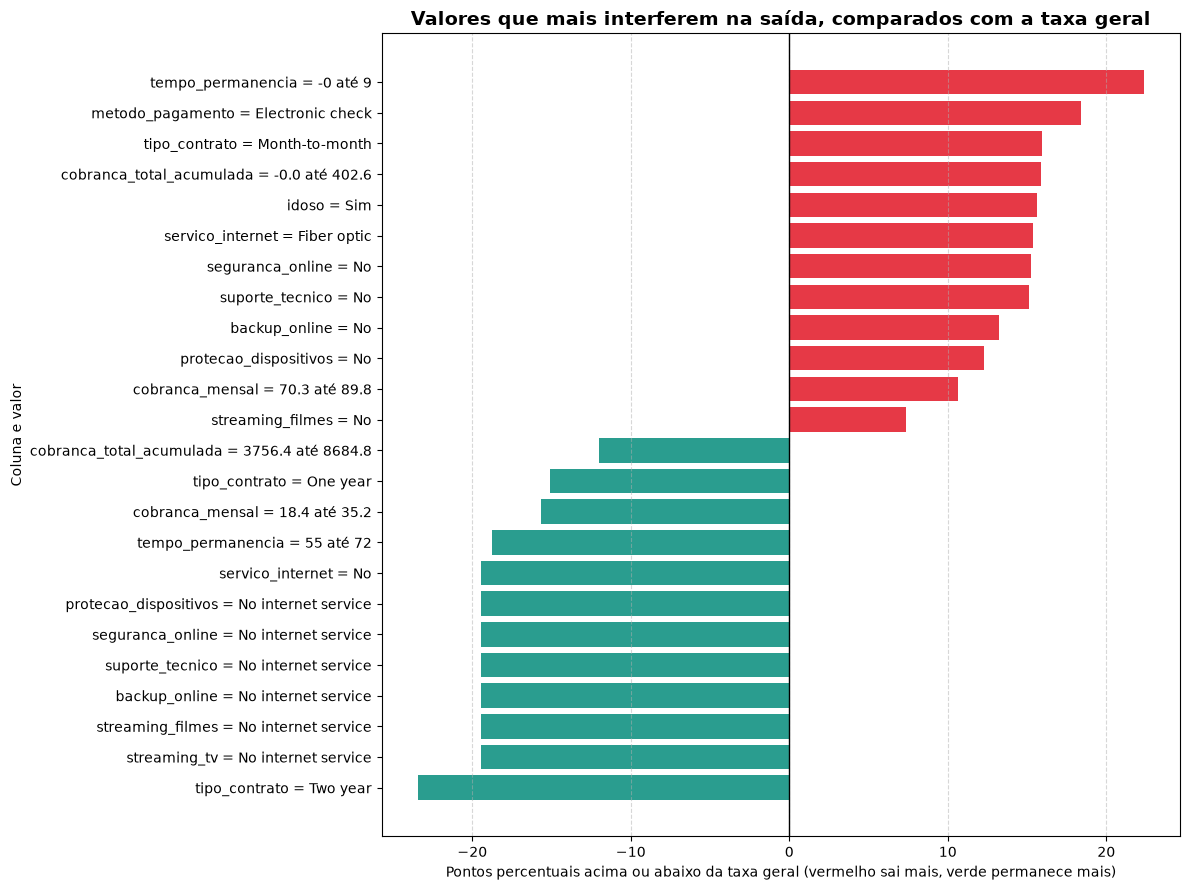

In [12]:
aumentam = relacao[relacao['diferenca_pp'] > 0].sort_values('diferenca_pp', ascending=False)
reduzem = relacao[relacao['diferenca_pp'] < 0].sort_values('diferenca_pp', ascending=True)

print('Valores que aumentam a possibilidade de sair, frente ao que aconteceu na base:')
for _, linha in aumentam.head(12).iterrows():
    print(
        f'Coluna {linha["coluna"]} com o valor "{linha["valor"]}" aumenta a possibilidade de sair: '
        f'taxa de {linha["taxa_saida"]:.1%} contra {taxa_geral:.1%} na base '
        f'({linha["diferenca_pp"]:+.1f} pontos percentuais; {int(linha["clientes"])} clientes).'
    )

print()
print('Valores que aumentam a possibilidade de permanecer:')
for _, linha in reduzem.head(12).iterrows():
    print(
        f'Coluna {linha["coluna"]} com o valor "{linha["valor"]}" reduz a possibilidade de sair: '
        f'taxa de {linha["taxa_saida"]:.1%} contra {taxa_geral:.1%} na base '
        f'({linha["diferenca_pp"]:+.1f} pontos percentuais; {int(linha["clientes"])} clientes).'
    )

extremos = pd.concat([aumentam.head(12), reduzem.head(12)], ignore_index=True)
extremos['descricao'] = extremos['coluna'] + ' = ' + extremos['valor'].astype(str)
extremos = extremos.sort_values('diferenca_pp', ascending=True)
cores = ['#E63946' if valor >= 0 else '#2A9D8F' for valor in extremos['diferenca_pp']]

plt.figure(figsize=(12, 9))
plt.barh(extremos['descricao'], extremos['diferenca_pp'], color=cores)
plt.axvline(0, color='black', linewidth=1)
plt.title('Valores que mais interferem na saída, comparados com a taxa geral', fontsize=14, fontweight='bold')
plt.xlabel('Pontos percentuais acima ou abaixo da taxa geral (vermelho sai mais, verde permanece mais)')
plt.ylabel('Coluna e valor')
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


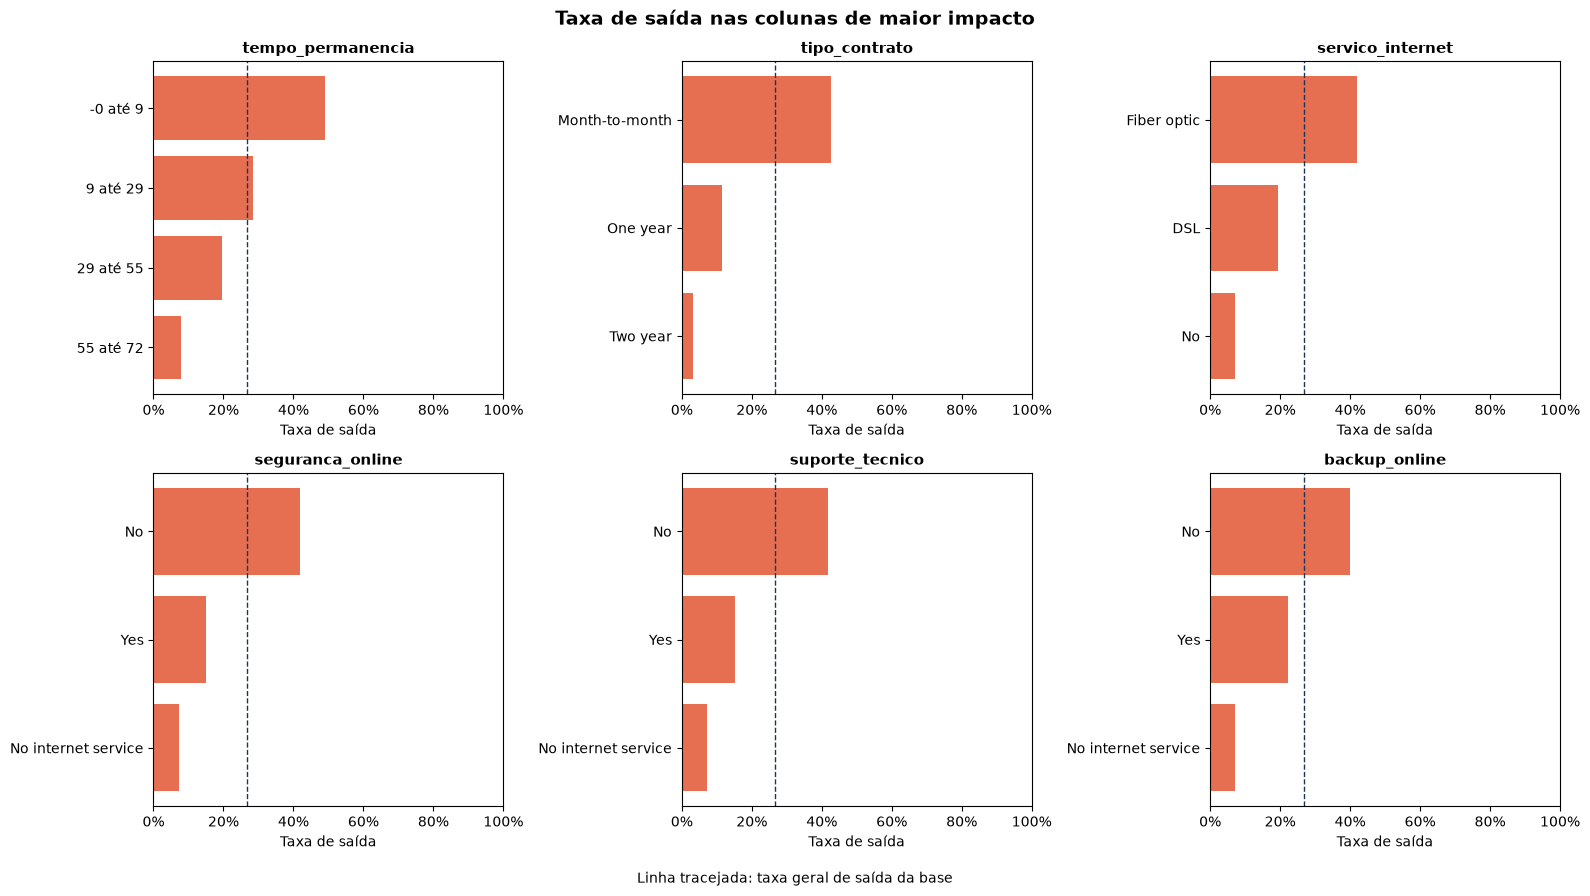

In [13]:
top_colunas = impacto_coluna['coluna'].head(6).tolist()
fig, eixos = plt.subplots(2, 3, figsize=(16, 9))
eixos = eixos.ravel()

for eixo, coluna in zip(eixos, top_colunas):
    dados = relacao[relacao['coluna'] == coluna].sort_values('taxa_saida', ascending=True)
    eixo.barh(dados['valor'].astype(str), dados['taxa_saida'], color='#E76F51')
    eixo.axvline(taxa_geral, color='#1D3557', linestyle='--', linewidth=1)
    eixo.set_title(coluna, fontsize=11, fontweight='bold')
    eixo.set_xlabel('Taxa de saída')
    eixo.set_ylabel('')
    eixo.set_xlim(0, 1)
    eixo.xaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _pos: f'{valor:.0%}'))

for eixo in eixos[len(top_colunas):]:
    eixo.axis('off')

fig.suptitle('Taxa de saída nas colunas de maior impacto', fontsize=14, fontweight='bold')
fig.text(0.5, 0.01, 'Linha tracejada: taxa geral de saída da base', ha='center', fontsize=10)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()


PIOR PERFIL: combinação dos valores que mais acompanharam a saída
- tempo_permanencia: "-0 até 9" (saiu 49.1% desse grupo, +22.4 p.p. frente à base, 1480 clientes)
- metodo_pagamento: "Electronic check" (saiu 45.1% desse grupo, +18.4 p.p. frente à base, 1888 clientes)
- tipo_contrato: "Month-to-month" (saiu 42.7% desse grupo, +16.0 p.p. frente à base, 3099 clientes)
- cobranca_total_acumulada: "-0.0 até 402.6" (saiu 42.6% desse grupo, +15.9 p.p. frente à base, 1410 clientes)
- idoso: "Sim" (saiu 42.3% desse grupo, +15.7 p.p. frente à base, 928 clientes)
- servico_internet: "Fiber optic" (saiu 42.1% desse grupo, +15.4 p.p. frente à base, 2477 clientes)
- seguranca_online: "No" (saiu 41.9% desse grupo, +15.2 p.p. frente à base, 2803 clientes)
- suporte_tecnico: "No" (saiu 41.8% desse grupo, +15.2 p.p. frente à base, 2791 clientes)
- backup_online: "No" (saiu 39.9% desse grupo, +13.2 p.p. frente à base, 2457 clientes)
- protecao_dispositivos: "No" (saiu 39.0% desse grupo, +12.3 p.p. frent

,coluna,valor,clientes,taxa_saida,diferenca_pp
52,tempo_permanencia,-0 até 9,1480,49.1%,+22.4 p.p.
17,metodo_pagamento,Electronic check,1888,45.1%,+18.4 p.p.
56,tipo_contrato,Month-to-month,3099,42.7%,+16.0 p.p.
7,cobranca_total_acumulada,-0.0 até 402.6,1410,42.6%,+15.9 p.p.
15,idoso,Sim,928,42.3%,+15.7 p.p.
38,servico_internet,Fiber optic,2477,42.1%,+15.4 p.p.
35,seguranca_online,No,2803,41.9%,+15.2 p.p.
49,suporte_tecnico,No,2791,41.8%,+15.2 p.p.
0,backup_online,No,2457,39.9%,+13.2 p.p.
28,protecao_dispositivos,No,2469,39.0%,+12.3 p.p.


,coluna,valor,clientes,taxa_saida,diferenca_pp
58,tipo_contrato,Two year,1347,3.3%,-23.4 p.p.
2,backup_online,No internet service,1233,7.2%,-19.5 p.p.
45,streaming_filmes,No internet service,1233,7.2%,-19.5 p.p.
40,servico_internet,No,1233,7.2%,-19.5 p.p.
37,seguranca_online,No internet service,1233,7.2%,-19.5 p.p.
51,suporte_tecnico,No internet service,1233,7.2%,-19.5 p.p.
48,streaming_tv,No internet service,1233,7.2%,-19.5 p.p.
30,protecao_dispositivos,No internet service,1233,7.2%,-19.5 p.p.
55,tempo_permanencia,55 até 72,1395,8.0%,-18.7 p.p.
6,cobranca_mensal,18.4 até 35.2,1409,11.0%,-15.7 p.p.


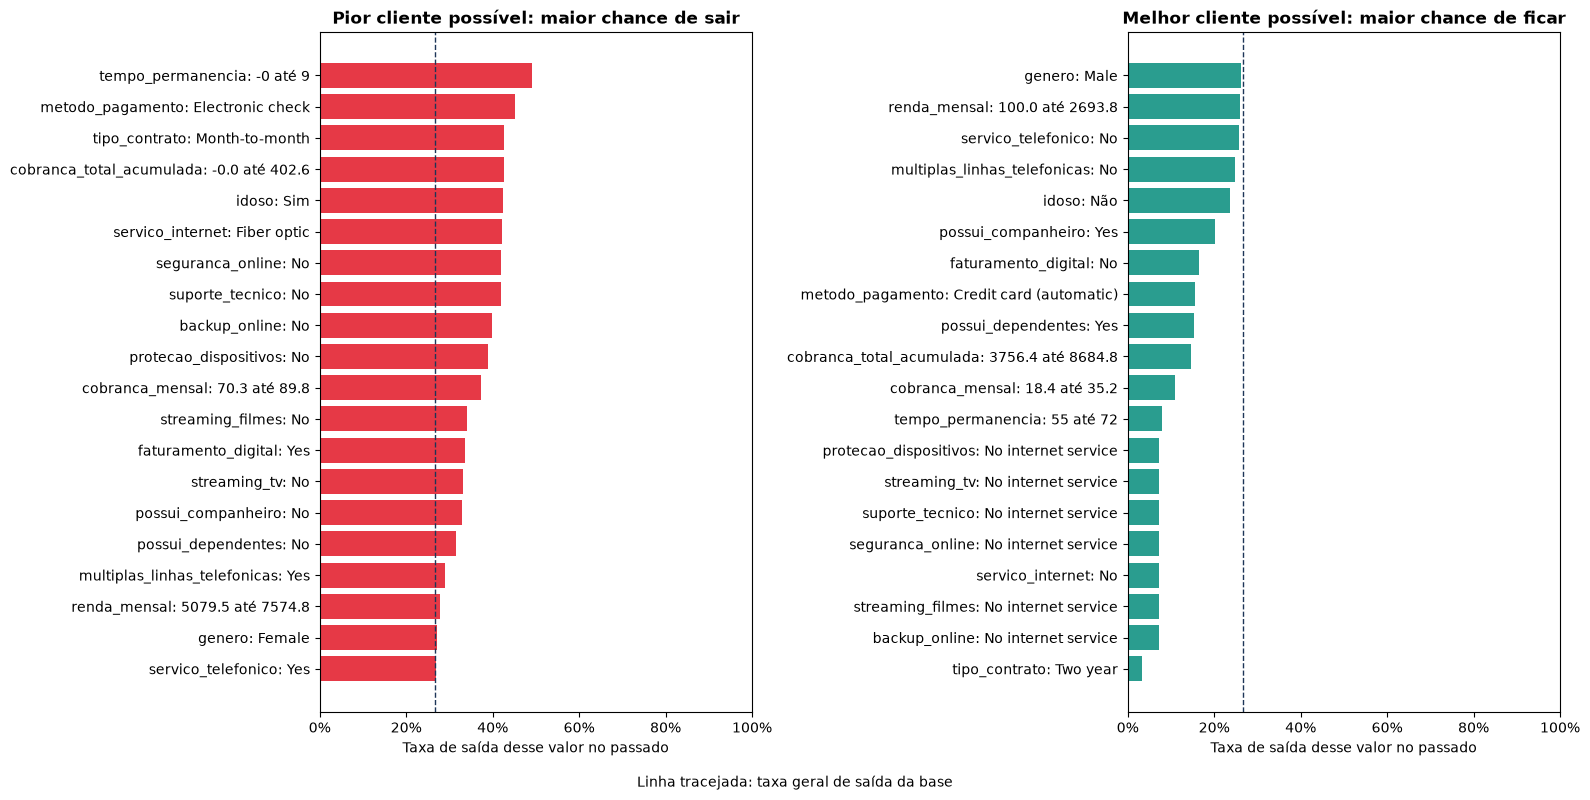

In [14]:
from IPython.display import display

indice_pior = relacao.groupby('coluna')['taxa_saida'].idxmax()
indice_melhor = relacao.groupby('coluna')['taxa_saida'].idxmin()

perfil_pior = relacao.loc[indice_pior].sort_values('taxa_saida', ascending=False).copy()
perfil_melhor = relacao.loc[indice_melhor].sort_values('taxa_saida', ascending=True).copy()


def tabela_perfil(perfil):
    tabela = perfil[['coluna', 'valor', 'clientes', 'taxa_saida', 'diferenca_pp']].copy()
    tabela['taxa_saida'] = tabela['taxa_saida'].map(lambda valor: f'{valor:.1%}')
    tabela['diferenca_pp'] = tabela['diferenca_pp'].map(lambda valor: f'{valor:+.1f} p.p.')
    return tabela


print('PIOR PERFIL: combinação dos valores que mais acompanharam a saída')
for _, linha in perfil_pior.iterrows():
    print(
        f'- {linha["coluna"]}: "{linha["valor"]}" '
        f'(saiu {linha["taxa_saida"]:.1%} desse grupo, {linha["diferenca_pp"]:+.1f} p.p. frente à base, '
        f'{int(linha["clientes"])} clientes)'
    )

print()
print('MELHOR PERFIL: combinação dos valores que mais acompanharam a permanência')
for _, linha in perfil_melhor.iterrows():
    print(
        f'- {linha["coluna"]}: "{linha["valor"]}" '
        f'(saiu {linha["taxa_saida"]:.1%} desse grupo, {linha["diferenca_pp"]:+.1f} p.p. frente à base, '
        f'{int(linha["clientes"])} clientes)'
    )

display(tabela_perfil(perfil_pior))
display(tabela_perfil(perfil_melhor))

fig, (eixo_pior, eixo_melhor) = plt.subplots(1, 2, figsize=(16, 8))

pior_plot = perfil_pior.sort_values('taxa_saida', ascending=True)
eixo_pior.barh(
    pior_plot['coluna'] + ': ' + pior_plot['valor'].astype(str),
    pior_plot['taxa_saida'],
    color='#E63946',
)
eixo_pior.axvline(taxa_geral, color='#1D3557', linestyle='--', linewidth=1)
eixo_pior.set_xlim(0, 1)
eixo_pior.set_title('Pior cliente possível: maior chance de sair', fontsize=12, fontweight='bold')
eixo_pior.set_xlabel('Taxa de saída desse valor no passado')
eixo_pior.xaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _pos: f'{valor:.0%}'))

melhor_plot = perfil_melhor.sort_values('taxa_saida', ascending=True)
eixo_melhor.barh(
    melhor_plot['coluna'] + ': ' + melhor_plot['valor'].astype(str),
    melhor_plot['taxa_saida'],
    color='#2A9D8F',
)
eixo_melhor.axvline(taxa_geral, color='#1D3557', linestyle='--', linewidth=1)
eixo_melhor.set_xlim(0, 1)
eixo_melhor.set_title('Melhor cliente possível: maior chance de ficar', fontsize=12, fontweight='bold')
eixo_melhor.set_xlabel('Taxa de saída desse valor no passado')
eixo_melhor.xaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _pos: f'{valor:.0%}'))

fig.text(0.5, 0.01, 'Linha tracejada: taxa geral de saída da base', ha='center', fontsize=10)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()
